WINNING MARGINS

Win Type Distribution:
   Mumbai Indians: 155 matches (12.7%)
   Chennai Super Kings: 148 matches (12.2%)
   Kolkata Knight Riders: 140 matches (11.5%)
   Rajasthan Royals: 123 matches (10.1%)
   Royal Challengers Bangalore: 114 matches (9.4%)
   Sunrisers Hyderabad: 102 matches (8.4%)
   Kings XI Punjab: 85 matches (7.0%)
   Delhi Daredevils: 67 matches (5.5%)
   Delhi Capitals: 58 matches (4.8%)
   Gujarat Titans: 47 matches (3.9%)
   Punjab Kings: 41 matches (3.4%)
   Lucknow Super Giants: 34 matches (2.8%)
   Royal Challengers Bengaluru: 29 matches (2.4%)
   Deccan Chargers: 29 matches (2.4%)
   Gujarat Lions: 13 matches (1.1%)
   Pune Warriors: 12 matches (1.0%)
   Rising Pune Supergiant: 10 matches (0.8%)
   Kochi Tuskers Kerala: 6 matches (0.5%)
   Rising Pune Supergiants: 5 matches (0.4%)

Average Margins:
   By Runs: nan runs (median: nan)
   By Wickets: nan wickets (median: nan)


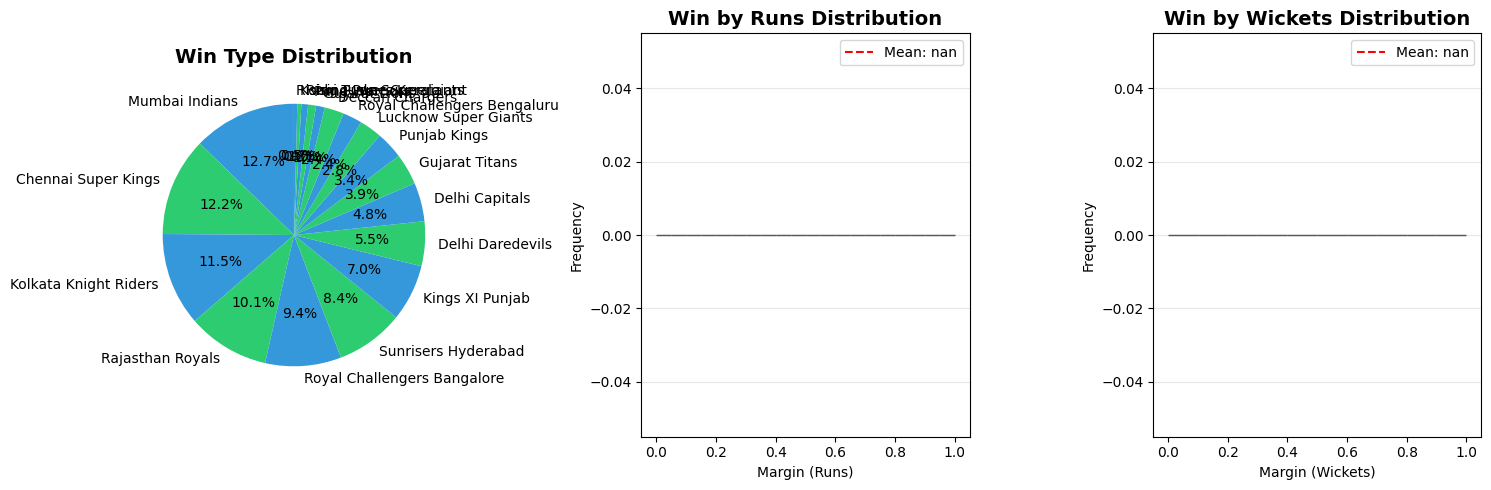

In [16]:
# Analyze winning margins
match_results = ipl.groupby('match_id').first()[['match_won_by', 'win_outcome', 'year']].dropna()

print("WINNING MARGINS")
print("="*80)

win_types = match_results['match_won_by'].value_counts()
print("\nWin Type Distribution:")
for wtype, count in win_types.items():
    print(f"   {wtype}: {count} matches ({count/len(match_results)*100:.1f}%)")

# Get margins
runs_wins = match_results[match_results['match_won_by'] == 'runs']['win_outcome'].astype(float)
wicket_wins = match_results[match_results['match_won_by'] == 'wickets']['win_outcome'].astype(float)

print(f"\nAverage Margins:")
print(f"   By Runs: {runs_wins.mean():.1f} runs (median: {runs_wins.median():.0f})")
print(f"   By Wickets: {wicket_wins.mean():.1f} wickets (median: {wicket_wins.median():.0f})")

# Visualization
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# 1. Win type pie
axes[0].pie(win_types.values, labels=win_types.index, autopct='%1.1f%%',
            colors=['#3498db', '#2ecc71'], startangle=90)
axes[0].set_title('Win Type Distribution', fontsize=14, fontweight='bold')

# 2. Runs margin distribution
axes[1].hist(runs_wins, bins=20, color='#3498db', edgecolor='black', alpha=0.8)
axes[1].axvline(runs_wins.mean(), color='red', linestyle='--', label=f'Mean: {runs_wins.mean():.1f}')
axes[1].set_title('Win by Runs Distribution', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Margin (Runs)')
axes[1].set_ylabel('Frequency')
axes[1].legend()
axes[1].grid(axis='y', alpha=0.3)

# 3. Wickets margin distribution
axes[2].hist(wicket_wins, bins=10, color='#2ecc71', edgecolor='black', alpha=0.8)
axes[2].axvline(wicket_wins.mean(), color='red', linestyle='--', label=f'Mean: {wicket_wins.mean():.1f}')
axes[2].set_title('Win by Wickets Distribution', fontsize=14, fontweight='bold')
axes[2].set_xlabel('Margin (Wickets)')
axes[2].set_ylabel('Frequency')
axes[2].legend()
axes[2].grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()
